# 05 · Series models

A recurrent model reads the slice models' outputs along a whole series and predicts the nine series labels and every slice again. Each section changes one thing against the current setting.

**Contents**
1. Setup and reference
2. Embedding, logit or both
3. Length
4. Slice loss on every series
5. Two backbones
6. Neighbour differences
7. Final ensemble

Needs `slices.csv` and `series.csv` (02), `outputs/features/` from `scripts/extract_features.py` (the five folds of both slice models of 04) and `outputs/series_runs/` from `scripts/train_series.py`.

No model is trained here. Each section prints the command of one of its runs; this notebook reads their saved predictions and scores them again.

In [1]:
import functools
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

from pe.consistency import make_consistent
from pe.data.prepare import IMAGE_LABEL, SERIES_LABELS, read_series, read_slices
from pe.metrics import SERIES_WEIGHTS, paired_bootstrap, score_by_label, series_losses
from pe.paths import REPO_ROOT, load_paths
from pe.series_training import SliceFeatures, series_scores
from pe.validation import validation_fold

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
PROCESSED, OUTPUTS = paths["processed_data_dir"], paths["outputs_dir"]
RUNS = OUTPUTS / "series_runs"
TO_BEAT = 0.3209  # LightGBM without images, five folds, test-like (03)
SLICES_ONLY = 0.2884  # SE-ResNeXt101 slices with the level from the other folds and label rates for the series, test-like (04)
DEFAULTS = {"input": "embedding", "epochs": 25, "lr": 5e-4, "wd": 0.01, "batch": 64, "hidden": 256, "dropout": 0.1, "length": None,
            "slice_loss": "metric", "no_neighbours": False, "no_flip": False, "limit": None}  # of scripts/train_series.py

slices, series = read_slices(PROCESSED / "slices.csv"), read_series(PROCESSED / "series.csv")
TRAIN = series[series["split"] == "train"]
print(f"{len(TRAIN):,} training series in 5 folds, {(~TRAIN['writer'].isin(['dcm4che-1.4.35', 'dcm4che-1.4.37'])).sum():,} test-like")

7,279 training series in 5 folds, 5,647 test-like


In [2]:
@functools.cache
def fold_data(k):
    '''The series of fold k in their order, and its validation arrays.'''
    names = TRAIN.loc[TRAIN["fold"] == k, "series"].reset_index(drop=True)
    return names, validation_fold(slices, series, k, names)


@functools.cache
def checked(run):
    '''A run's probabilities before the fix, after checking its fold and scoring it again against its scores.json.'''
    config, saved = (json.loads((RUNS / run / name).read_text()) for name in ("config.json", "scores.json"))
    names, fold = fold_data(config["fold"])
    assert pd.read_csv(RUNS / run / "val.csv", dtype=str)["series"].equals(names.astype(str)), run
    p_series, p_image = np.load(RUNS / run / "val_p_series.npy"), np.load(RUNS / run / "val_p_image.npy")
    scores = series_scores(fold, p_series, p_image)
    assert all(np.isclose(scores[key], saved[key], rtol=0, atol=1e-9) for key in scores), run
    return p_series, p_image, {**scores, "train loss": saved["train loss"], "minutes": saved["minutes"]}


@functools.cache
def oof(parts, weights=None):
    '''Loss and weight of every training series after the fix, out-of-fold; `parts` are run names with {fold}, whose
    probabilities are averaged (with `weights`) before the fix.'''
    w = np.ones(len(parts)) if weights is None else np.asarray(weights, float)
    assert len(w) == len(parts), "one weight per run"
    w = w / w.sum()
    tables, fixed = [], []
    for k in range(5):
        names, fold = fold_data(k)
        found = [checked(part.format(fold=k)) for part in parts]
        p_series, p_image = (sum(wi * f[i] for wi, f in zip(w, found)) for i in (0, 1))
        fixed_series, fixed_image = make_consistent(p_series, fold.image_series, p_image, can_raise=fold.main)
        loss, weight = series_losses(fold.y_series, fixed_series, fold.image_series, fold.y_image, fixed_image)
        tables.append(pd.DataFrame({"fold": k, "series": names, "loss": loss, "weight": weight, "test-like": fold.test_like}))
        fixed.append((fixed_series, fixed_image))
    return pd.concat(tables, ignore_index=True), fixed


def scores(table):
    ratio = lambda part: part["loss"].sum() / part["weight"].sum()
    return {"test-like": round(float(ratio(table[table["test-like"]])), 4), "full": round(float(ratio(table)), 4), "rare writers": round(float(ratio(table[~table["test-like"]])), 4)}


def option(value):
    '''An option is a run name with {fold}, a tuple of them (averaged) or (tuple, weights).'''
    if isinstance(value, str):
        return (value,), None
    return (value[0], value[1]) if isinstance(value[0], tuple) else (value, None)


def compare(options, reference, full=False):
    '''One row per option: the out-of-fold test-like score (and with `full` the full and rare-writer scores) and the paired
    series bootstrap of its difference to `reference`, test-like.'''
    base = oof(*option(options[reference]))[0]
    rows = {}
    for name, value in options.items():
        table = oof(*option(value))[0]
        rows[name] = {**scores(table), "difference": ""}
        if name != reference:
            assert table["series"].equals(base["series"]) and np.allclose(table["weight"], base["weight"])
            like = table["test-like"].to_numpy()
            d = paired_bootstrap(base["loss"][like], table["loss"][like], base["weight"][like])
            rows[name]["difference"] = f"{d['mean']:+.4f} [{d['low']:+.4f}, {d['high']:+.4f}]"
    table = pd.DataFrame(rows).T.astype({"test-like": float, "full": float, "rare writers": float}).round(4)
    return table if full else table[["test-like", "difference"]]


def seeds(name, last=3):
    return tuple(f"{name}_f{{fold}}_s{seed}" for seed in range(1, last + 1))


def command(run):
    '''The command of a run: only the arguments that differ from the defaults.'''
    config = json.loads((RUNS / run / "config.json").read_text())
    parts = [f"--{key.replace('_', '-')}" + ("" if value is True else f" {value}") for key, value in config.items() if key in DEFAULTS and value != DEFAULTS[key]]
    return " ".join(["python scripts/train_series.py --name", run, "--backbones", config["backbones"], "--fold", str(config["fold"]), "--seed", str(config["seed"]), *parts])

## 1. Setup and reference

- **Features:** series model k is trained on the four other folds with the outputs of slice model k, and scored on fold k. Slice model k was trained on those four folds, so their features are in-sample; fold k is new to it, as the test set will be.
- **Model:** a bidirectional GRU (256 per direction) over the series' main-stack slices in body order. Each slice gives its features and their differences to the slices before and after. A head on every step predicts the slice; the series head reads the steps pooled by maximum and by attention.
- **Loss:** the competition metric on each batch: the nine series labels with their weights, and the slices of the series with PE with 0.0736 × q, q being the series' share of slices with PE. The denominator is the expected weight of a series, the same for every batch.
- **Training:** AdamW, learning rate 5e-4 with warm-up and cosine decay, weight decay 0.01, batch 64, 25 epochs, half the series reversed along the body. The last epoch counts; the choices between options use the out-of-fold scores.
- **Scoring:** the five folds out-of-fold, after the consistency fix: of a consistent positive and a consistent negative version of each series, the one that changes the predictions least is kept.
- **Rule:** an option is adopted when the 95% interval of its difference to the current setting (option − current, test-like, paired series bootstrap) lies below 0; the current setting is the row without a difference. Sections 2–6 run 5 folds and seed 1.

**Reference:** SE-ResNeXt101's 2,048 embedding values per slice. **Question:** How much does it gain over the slice model alone?

In [3]:
tests = subprocess.run([sys.executable, "-m", "pytest", "tests/test_consistency.py", "tests/test_series_training.py", "-q", "--color=no", "-p", "no:cacheprovider", "-W", "ignore"],
                       cwd=REPO_ROOT, capture_output=True, text=True)
print(tests.stdout.strip().splitlines()[-1])
assert tests.returncode == 0, tests.stdout
REFERENCE = "s1_ref_f{fold}_s1"
print(command("s1_ref_f0_s1"))
columns = ["test-like", "slices' share", "violations before the fix"]
per_fold = pd.DataFrame({k: checked(REFERENCE.format(fold=k))[2] for k in range(5)}).T[columns].rename_axis("fold")
display(per_fold.astype({"violations before the fix": int}).round(4))
table = oof((REFERENCE,))[0]
like = table[table["test-like"]]
print(f"five folds, test-like: {scores(table)['test-like']} (seed 2: {scores(oof(('s1_ref_f{fold}_s2',))[0])['test-like']})")
print("series breaking a rule before the fix, mean per fold:", per_fold["violations before the fix"].mean())
print(f"before the fix, test-like: {sum(checked(REFERENCE.format(fold=k))[2]['test-like before the fix'] * like.loc[like['fold'] == k, 'weight'].sum() for k in range(5)) / like['weight'].sum():.4f}")
print(f"to beat: {SLICES_ONLY} with the slice model alone (04), {TO_BEAT} without images (03)")

14 passed in 4.09s
python scripts/train_series.py --name s1_ref_f0_s1 --backbones seresnext101 --fold 0 --seed 1


,test-like,slices' share,violations before the fix
fold,,,
0,0.2076,0.4848,351
1,0.2094,0.5451,360
2,0.2181,0.5180,290
3,0.2008,0.5266,306
4,0.1911,0.5173,304


five folds, test-like: 0.2054 (seed 2: 0.2056)
series breaking a rule before the fix, mean per fold: 322.2
before the fix, test-like: 0.2051
to beat: 0.2884 with the slice model alone (04), 0.3209 without images (03)


Three series of fold 0 with PE (the 25%, 50% and 75% quantiles of q among the test-like ones): the slice model of fold 0 alone against the series model, along the main stack.

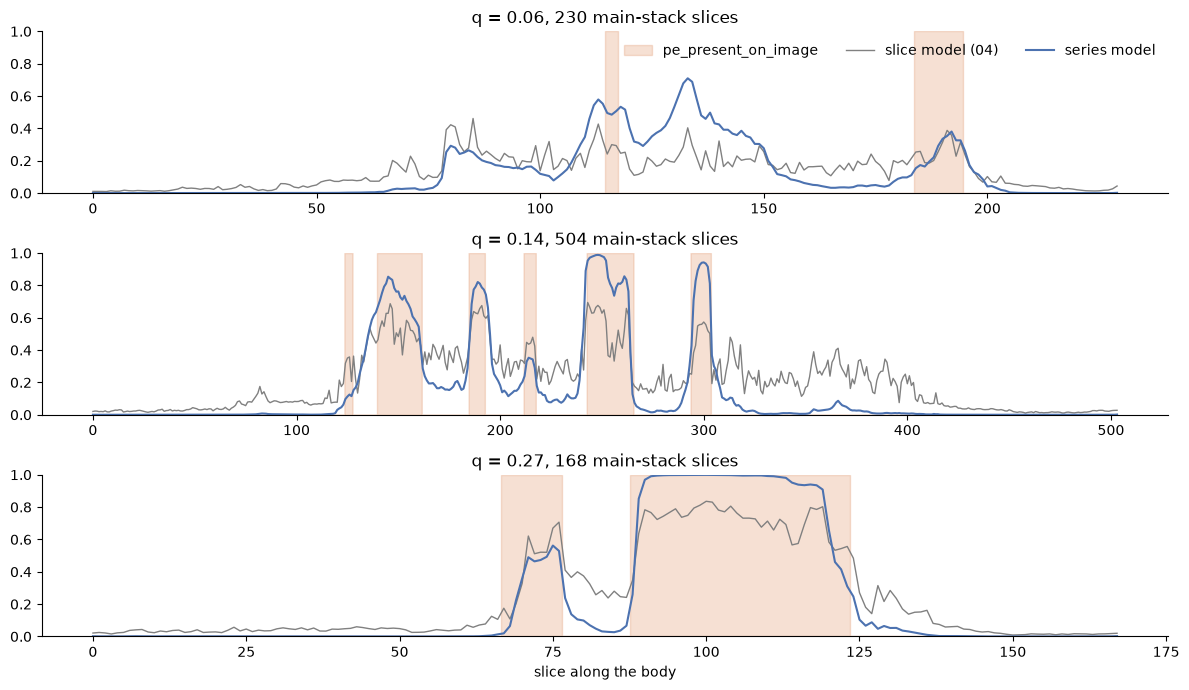

In [4]:
names, fold = fold_data(0)
_, p_image, _ = checked("s1_ref_f0_s1")
table0 = slices[slices["series"].isin(names)]
features = SliceFeatures(OUTPUTS / "features", 0, ["seresnext101"], "logit")
feature_rows = features.rows_of(table0)
main_rows = np.flatnonzero(fold.main)
assert features.index.iloc[feature_rows][["series", "image"]].reset_index(drop=True).equals(table0.iloc[main_rows][["series", "image"]].astype(str).reset_index(drop=True))
slice_model = expit(features[feature_rows][:, 0])
q = pd.Series(fold.y_image).groupby(fold.image_series).mean()
candidates = q[(q > 0) & fold.test_like[q.index]].sort_values()
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharey=True)
for ax, share in zip(axes, (0.25, 0.5, 0.75)):
    i = candidates.index[int(share * (len(candidates) - 1))]
    rows = np.flatnonzero(fold.image_series[main_rows] == i)
    x = np.arange(len(rows))
    ax.fill_between(x, 0, fold.y_image[main_rows[rows]], step="mid", color="#DD8452", alpha=0.25, label="pe_present_on_image")
    ax.plot(x, slice_model[rows], color="gray", lw=1, label="slice model (04)")
    ax.plot(x, p_image[main_rows[rows]], color="#4C72B0", lw=1.5, label="series model")
    ax.set(title=f"q = {q[i]:.2f}, {len(rows)} main-stack slices", ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(loc="upper right", frameon=False, ncol=3)
axes[-1].set_xlabel("slice along the body")
plt.tight_layout()

### 1.1 Key findings

- **The series model cuts the score from 0.2884 to 0.2054** (test-like, five folds), against 0.3209 without images. It now predicts the series labels too, which the slice models left at the label rates.
- **The slices are about half of the score** (48–55% by fold).
- **The fix costs little:** 290–360 series per fold break a rule before it, and it raises the test-like score from 0.2051 to 0.2054.
- **A second seed gives 0.2056,** 0.0001 above the first.
- **In these three series the series model is sharper than the slice model:** it pushes the slices between runs of PE towards 0 and the runs up. Where the slice model is unsure (top), it pushes a wrong peak up as well.

## 2. Embedding, logit or both

**Question:** Does the series model need the 2,048 embedding values of each slice, or is the slice model's logit enough?

| Input | Values per slice | Into the GRU, with the differences to the neighbours |
|---|---|---|
| embedding | 2,048 | 6,144 |
| logit | 1 | 3 |
| embedding + logit | 2,049 | 6,147 |

In [5]:
print(command("s2_logit_f0_s1"))
inputs = {"embedding": REFERENCE, "logit": "s2_logit_f{fold}_s1", "embedding + logit": "s2_both_f{fold}_s1"}
compare(inputs, reference="embedding")

python scripts/train_series.py --name s2_logit_f0_s1 --backbones seresnext101 --fold 0 --seed 1 --input logit


,test-like,difference
embedding,0.2054,
logit,0.2062,"+0.0008 [-0.0026, +0.0041]"
embedding + logit,0.2056,"+0.0002 [-0.0006, +0.0010]"


### 2.1 Key findings

- **The embedding stays: neither the logit alone (0.2062) nor both (0.2056) beat it (0.2054);** both intervals include 0.
- **With the neighbour differences, one number per slice does almost as well as 2,048.**

## 3. Length

**Question:** Series have 63 to 716 main-stack slices (median 233). Does resampling every series to 192 slices, and the outputs back to the series' own slices, help the GRU?

In [6]:
print(command("s3_len192_f0_s1"))
compare({"own length": REFERENCE, "192 slices": "s3_len192_f{fold}_s1"}, reference="own length")

python scripts/train_series.py --name s3_len192_f0_s1 --backbones seresnext101 --fold 0 --seed 1 --length 192


,test-like,difference
own length,0.2054,
192 slices,0.2053,"-0.0001 [-0.0010, +0.0008]"


### 3.1 Key findings

- **The series keep their own length:** 192 slices give 0.2053 against 0.2054, interval −0.0010 to +0.0008.

## 4. Slice loss on every series

The metric reads slices only in series with PE. **Question:** Does training the slice head on the series without PE too, at the mean q of the others, help? It should break fewer rules, since a negative series with one slice above 0.5 needs a fix.

In [7]:
print(command("s4_all_f0_s1"))
print("series breaking a rule before the fix, mean per fold:", {name: float(np.mean([checked(run.format(fold=k))[2]["violations before the fix"] for k in range(5)])) for name, run in {"series with PE": REFERENCE, "every series": "s4_all_f{fold}_s1"}.items()})
compare({"series with PE": REFERENCE, "every series": "s4_all_f{fold}_s1"}, reference="series with PE")

python scripts/train_series.py --name s4_all_f0_s1 --backbones seresnext101 --fold 0 --seed 1 --slice-loss all


series breaking a rule before the fix, mean per fold: {'series with PE': 322.2, 'every series': 106.4}


,test-like,difference
series with PE,0.2054,
every series,0.2269,"+0.0215 [+0.0175, +0.0260]"


### 4.1 Key findings

- **The slice loss stays on the series with PE: every series is 0.0215 worse** (0.2269).
- **Fewer series break a rule (106 against 322 per fold), but that does not pay:** the fix was cheap anyway (section 1).

## 5. Two backbones

**Question:** How should ConvNeXt Tiny join SE-ResNeXt101: inside one series model, or as a separate series model averaged with it?

Every row below is built from these series models. All are the same GRU; only what it reads per slice differs (the values before the neighbour differences):

| model | reads per slice | values |
|---|---|---|
| SE embedding | the SE-ResNeXt101 slice model's embedding | 2,048 |
| SE logit | that slice model's PE logit | 1 |
| SE (embedding + logit) | both, in one model (section 2) | 2,049 |
| ConvNeXt embedding | the ConvNeXt Tiny slice model's embedding | 768 |
| ConvNeXt logit | that slice model's PE logit | 1 |
| joint embedding | both backbones' embeddings side by side, in one model | 2,816 |
| joint logit | both backbones' logits side by side, in one model | 2 |

- **A + B:** A and B trained separately; their probabilities are averaged with equal weights before the fix.
- **2 seeds:** the same model trained with seeds 1 and 2 and averaged the same way. It shows what averaging alone gives, and gives a joint model the same averaging as a pair of separate models.

The three tables: each model alone, against SE embedding; averages of models, against SE embedding; ConvNeXt added to the best pair, SE embedding + SE logit.

In [8]:
print(command("s5_joint_f0_s1"))
single = {"SE embedding": REFERENCE, "ConvNeXt embedding": "s5_cnx_f{fold}_s1", "ConvNeXt logit": "s5_cnxlogit_f{fold}_s1",
          "joint embedding": "s5_joint_f{fold}_s1", "joint embedding, 2 seeds": seeds("s5_joint", 2), "joint logit": "s5_jointlogit_f{fold}_s1", "joint logit, 2 seeds": seeds("s5_jointlogit", 2)}
display(compare(single, reference="SE embedding"))
SE, SE2, LOGIT, CNX, CNXLOGIT = REFERENCE, "s1_ref_f{fold}_s2", "s2_logit_f{fold}_s1", "s5_cnx_f{fold}_s1", "s5_cnxlogit_f{fold}_s1"
averages = {"SE embedding": SE, "SE embedding, 2 seeds": (SE, SE2), "SE embedding + SE (embedding + logit)": (SE, "s2_both_f{fold}_s1"), "SE embedding + SE logit": (SE, LOGIT),
            "SE embedding + ConvNeXt embedding": (SE, CNX), "SE embedding + ConvNeXt logit": (SE, CNXLOGIT), "SE embedding + joint logit": (SE, "s5_jointlogit_f{fold}_s1"), "SE logit + ConvNeXt logit": (LOGIT, CNXLOGIT),
            "SE embedding + SE logit + ConvNeXt embedding": (SE, LOGIT, CNX), "SE embedding + SE logit + ConvNeXt logit": (SE, LOGIT, CNXLOGIT), "all four": (SE, LOGIT, CNX, CNXLOGIT)}
display(compare(averages, reference="SE embedding"))
pair = {"SE embedding + SE logit": (SE, LOGIT), "+ ConvNeXt embedding": (SE, LOGIT, CNX), "+ ConvNeXt logit": (SE, LOGIT, CNXLOGIT), "+ both": (SE, LOGIT, CNX, CNXLOGIT)}
display(compare(pair, reference="SE embedding + SE logit"))
print("+ ConvNeXt logit against + ConvNeXt embedding:", compare({"embedding": pair["+ ConvNeXt embedding"], "logit": pair["+ ConvNeXt logit"]}, reference="embedding").loc["logit", "difference"])

python scripts/train_series.py --name s5_joint_f0_s1 --backbones seresnext101,convnext_tiny --fold 0 --seed 1


,test-like,difference
SE embedding,0.2054,
ConvNeXt embedding,0.2260,"+0.0206 [+0.0161, +0.0254]"
ConvNeXt logit,0.2195,"+0.0141 [+0.0097, +0.0188]"
joint embedding,0.2443,"+0.0388 [+0.0336, +0.0445]"
"joint embedding, 2 seeds",0.2426,"+0.0372 [+0.0319, +0.0430]"
joint logit,0.2197,"+0.0142 [+0.0098, +0.0190]"
"joint logit, 2 seeds",0.2196,"+0.0142 [+0.0097, +0.0189]"


,test-like,difference
SE embedding,0.2054,
"SE embedding, 2 seeds",0.2049,"-0.0005 [-0.0008, -0.0001]"
SE embedding + SE (embedding + logit),0.2050,"-0.0005 [-0.0009, -0.0001]"
SE embedding + SE logit,0.1985,"-0.0069 [-0.0090, -0.0050]"
SE embedding + ConvNeXt embedding,0.2017,"-0.0037 [-0.0056, -0.0018]"
SE embedding + ConvNeXt logit,0.1990,"-0.0065 [-0.0087, -0.0042]"
SE embedding + joint logit,0.1992,"-0.0063 [-0.0086, -0.0039]"
SE logit + ConvNeXt logit,0.2035,"-0.0019 [-0.0054, +0.0015]"
SE embedding + SE logit + ConvNeXt embedding,0.1969,"-0.0086 [-0.0108, -0.0064]"
SE embedding + SE logit + ConvNeXt logit,0.1972,"-0.0082 [-0.0107, -0.0057]"


,test-like,difference
SE embedding + SE logit,0.1985,
+ ConvNeXt embedding,0.1969,"-0.0016 [-0.0028, -0.0004]"
+ ConvNeXt logit,0.1972,"-0.0013 [-0.0024, -0.0001]"
+ both,0.1979,"-0.0006 [-0.0021, +0.0009]"


+ ConvNeXt logit against + ConvNeXt embedding: +0.0004 [-0.0005, +0.0012]


### 5.1 Key findings

- **ConvNeXt alone is worse than SE-ResNeXt101** (embedding 0.2260, logit 0.2195), although its slices tied in 04.
- **The joint models are worse than SE-ResNeXt101 alone,** the joint embedding by far (0.2443), and a second seed does not rescue them.
- **The gain comes from averaging separate models, above all an embedding model with a logit model:** SE embedding + SE logit gives 0.1985 (−0.0069), more than SE embedding + ConvNeXt embedding (0.2017). Two seeds of the same model give only −0.0005, and SE embedding + the model reading both only −0.0005: the two inputs help as two models, not as one.
- **ConvNeXt adds a little on top of the SE pair:** −0.0016 with its embedding model and −0.0013 with its logit model, both intervals below 0; adding both gives −0.0006.
- **Chosen: SE embedding + SE logit + ConvNeXt embedding, equal weights.** The other three-model set scores 0.1972 against 0.1969; compared directly, +0.0004, interval −0.0005 to +0.0012, too close to call.

## 6. Neighbour differences

**Question:** The GRU carries what it has seen along the series. Does it still need each slice's differences to the slices before and after, [f, f − previous, f − next], or is [f] enough? Tested on the four models of section 5, seed 1.

In [9]:
print(command("s7_noneigh_f0_s1"))
pairs = {"SE embedding": (REFERENCE, "s7_noneigh_f{fold}_s1"), "SE logit": ("s2_logit_f{fold}_s1", "s7_selogit_nn_f{fold}_s1"), "ConvNeXt embedding": ("s5_cnx_f{fold}_s1", "s7_cnxemb_nn_f{fold}_s1"), "ConvNeXt logit": ("s5_cnxlogit_f{fold}_s1", "s7_cnxlogit_nn_f{fold}_s1")}
rows = {}
for name, (with_, without) in pairs.items():
    table = compare({"with": with_, "without": without}, reference="with")
    rows[name] = {"[f, f − previous, f − next]": table.loc["with", "test-like"], "[f]": table.loc["without", "test-like"], "difference": table.loc["without", "difference"]}
pd.DataFrame(rows).T.astype({"[f, f − previous, f − next]": float, "[f]": float})

python scripts/train_series.py --name s7_noneigh_f0_s1 --backbones seresnext101 --fold 0 --seed 1 --no-neighbours


,"[f, f − previous, f − next]",[f],difference
SE embedding,0.2054,0.1999,"-0.0055 [-0.0067, -0.0043]"
SE logit,0.2062,0.2071,"+0.0009 [+0.0005, +0.0013]"
ConvNeXt embedding,0.2260,0.2213,"-0.0048 [-0.0060, -0.0036]"
ConvNeXt logit,0.2195,0.2199,"+0.0004 [-0.0000, +0.0008]"


**The three models of the final ensemble together:** SE embedding, SE logit and ConvNeXt embedding (ConvNeXt logit is not in it). Each row trains them with other inputs; their probabilities are averaged, then scored.

| row | inputs |
|---|---|
| all three with the differences (section 5) | all three [f, f − previous, f − next]; the reference, as in section 5 |
| all three [f] | all three [f] |
| embeddings [f], logit with the differences | each model with its better input in the table above |

**test-like** is the score of the averaged ensemble; **difference** is the row minus the reference, with the 95% interval of the paired series bootstrap.

In [10]:
WITH = (REFERENCE, "s2_logit_f{fold}_s1", "s5_cnx_f{fold}_s1")
sets = {"all three with the differences (section 5)": WITH, "all three [f]": ("s7_noneigh_f{fold}_s1", "s7_selogit_nn_f{fold}_s1", "s7_cnxemb_nn_f{fold}_s1"),
        "embeddings [f], logit with the differences": ("s7_noneigh_f{fold}_s1", "s2_logit_f{fold}_s1", "s7_cnxemb_nn_f{fold}_s1")}
compare(sets, reference="all three with the differences (section 5)")

,test-like,difference
all three with the differences (section 5),0.1969,
all three [f],0.1957,"-0.0012 [-0.0017, -0.0007]"
"embeddings [f], logit with the differences",0.1955,"-0.0014 [-0.0019, -0.0009]"


### 6.1 Key findings

- **Both embedding models are better without the differences: SE 0.1999 (−0.0055), ConvNeXt 0.2213 (−0.0048).** The GRU carries the neighbours itself.
- **The logit models do not gain without them: SE +0.0009, ConvNeXt +0.0004 (its interval reaches 0).** The differences add no information the GRU cannot see; they only put the neighbours in each step, which helps a model that reads one value per slice.
- **Each model with its better input gives the best set: 0.1955 against 0.1969.** Section 7 uses it.

## 7. Final ensemble

**Question:** What does the final ensemble score? It is the set of section 5, each model with its better input of section 6: SE embedding [f], SE logit [f, f − previous, f − next] and ConvNeXt embedding [f], seed 1, equal weights. The ensemble averages the three models' probabilities before one fix. On the test set series model k reads the outputs of slice model k, and the five folds are averaged before the fix.

The tables: the final built up step by step, against the reference of section 1; the final against the section 5 set (all three with the differences) with one and three seeds; the final against other sets of the same models.

The per-label table splits the final score by label (test-like series): each label's log loss with the label rates, as the slice models left them, and with the ensemble.

In [11]:
print(command("s7_cnxemb_nn_f0_s1"))
SE_F, SE_LOGIT, CNX_F, CNX_LOGIT = "s7_noneigh_f{fold}_s1", "s6_selogit_f{fold}_s1", "s7_cnxemb_nn_f{fold}_s1", "s6_cnxlogit_f{fold}_s1"
FINAL = (SE_F, SE_LOGIT, CNX_F)
components = {"SE embedding (section 1)": REFERENCE, "SE embedding [f]": SE_F, "SE logit": SE_LOGIT, "ConvNeXt embedding [f]": CNX_F,
              "SE embedding [f] + SE logit": (SE_F, SE_LOGIT), "final: + ConvNeXt embedding [f]": FINAL}
display(compare(components, reference="SE embedding (section 1)", full=True))
SECTION5 = [seeds(f"s6_{name}") for name in ("seemb", "selogit", "cnxemb")]
display(compare({"final": FINAL, "section 5 set, seed 1": tuple(runs[0] for runs in SECTION5), "section 5 set, 3 seeds": sum(SECTION5, ())}, reference="final"))
others = {"final": FINAL, "ConvNeXt logit instead": (SE_F, SE_LOGIT, CNX_LOGIT), "all four": (SE_F, SE_LOGIT, CNX_F, CNX_LOGIT),
          "all four, 1/3, 1/3, 1/6, 1/6": ((SE_F, SE_LOGIT, CNX_F, CNX_LOGIT), (2, 2, 1, 1))}
compare(others, reference="final")

python scripts/train_series.py --name s7_cnxemb_nn_f0_s1 --backbones convnext_tiny --fold 0 --seed 1 --no-neighbours


,test-like,full,rare writers,difference
SE embedding (section 1),0.2054,0.2089,0.2182,
SE embedding [f],0.1999,0.2036,0.2136,"-0.0055 [-0.0067, -0.0043]"
SE logit,0.2062,0.2107,0.2231,"+0.0008 [-0.0026, +0.0041]"
ConvNeXt embedding [f],0.2213,0.2249,0.2349,"+0.0158 [+0.0113, +0.0205]"
SE embedding [f] + SE logit,0.1975,0.2017,0.2130,"-0.0079 [-0.0102, -0.0056]"
final: + ConvNeXt embedding [f],0.1955,0.1993,0.2095,"-0.0099 [-0.0123, -0.0075]"


,test-like,difference
final,0.1955,
"section 5 set, seed 1",0.1969,"+0.0014 [+0.0009, +0.0019]"
"section 5 set, 3 seeds",0.1966,"+0.0011 [+0.0006, +0.0016]"


,test-like,difference
final,0.1955,
ConvNeXt logit instead,0.1966,"+0.0011 [+0.0003, +0.0019]"
all four,0.1970,"+0.0014 [+0.0008, +0.0020]"
"all four, 1/3, 1/3, 1/6, 1/6",0.1956,"+0.0001 [-0.0003, +0.0005]"


In [12]:
final, fixed = oof(FINAL)
y_series, p_rates, p_final, image_series, y_image, p_image = [], [], [], [], [], []
offset = 0
for k in range(5):
    names, fold = fold_data(k)
    keep = fold.test_like
    new_row = np.cumsum(keep) - 1 + offset
    on = keep[fold.image_series]
    y_series.append(fold.y_series[keep]); p_rates.append(fold.p_series[keep]); p_final.append(fixed[k][0][keep])
    image_series.append(new_row[fold.image_series[on]]); y_image.append(fold.y_image[on]); p_image.append(fixed[k][1][on])
    offset += keep.sum()
arrays = [np.concatenate(a) for a in (y_series, p_final, image_series, y_image, p_image)]
by_label = pd.DataFrame(score_by_label(*arrays)).T
by_label["label rates"] = pd.DataFrame(score_by_label(arrays[0], np.concatenate(p_rates), *arrays[2:])).T.loc[SERIES_LABELS, "log loss"]
by_label["weight"] = pd.Series(SERIES_WEIGHTS, index=SERIES_LABELS)
assert np.isclose(by_label["share of the score"].sum(), final.loc[final["test-like"], "loss"].sum() / final.loc[final["test-like"], "weight"].sum())
by_label[["weight", "label rates", "log loss", "share of the score"]].round(4)

,weight,label rates,log loss,share of the score
negative_exam_for_pe,0.0736,0.6073,0.3071,0.0121
indeterminate,0.0920,0.1110,0.0850,0.0042
rightsided_pe,0.0626,0.5372,0.2459,0.0083
leftsided_pe,0.0626,0.4910,0.2562,0.0086
central_pe,0.1877,0.2036,0.0969,0.0098
rv_lv_ratio_gte_1,0.2347,0.3684,0.2109,0.0266
rv_lv_ratio_lt_1,0.0782,0.4235,0.3068,0.0129
chronic_pe,0.1043,0.1646,0.1462,0.0082
acute_and_chronic_pe,0.1043,0.0960,0.0731,0.0041
pe_present_on_image,NaN,NaN,0.2177,0.1007


### 7.1 Key findings

- **The final ensemble scores 0.1955** (test-like; full 0.1993, rare writers 0.2095), 0.0099 better than the reference and 0.0929 better than the slice model alone.
- **The inputs gain more than the seeds:** the section 5 set scores 0.1969 with one seed and 0.1966 with three, both worse than the final (+0.0011 with three).
- **ConvNeXt embedding stays the third model, with equal weights:** ConvNeXt logit instead is worse (0.1966), and so is adding it as a fourth model (0.1970); splitting ConvNeXt's 1/3 between its two models gives 0.1956.
- **The slices are half of the final score** (0.1007 of 0.1955). Among the series labels rv_lv_ratio_gte_1 costs most (0.0266), as it has the highest weight.
- **The series model gains most where the label rates are worst:** negative_exam_for_pe from 0.61 to 0.31, the two sides from about 0.5 to 0.25. The chronic labels and indeterminate gain least (0.165 to 0.146, 0.096 to 0.073, 0.111 to 0.085).

## Summary

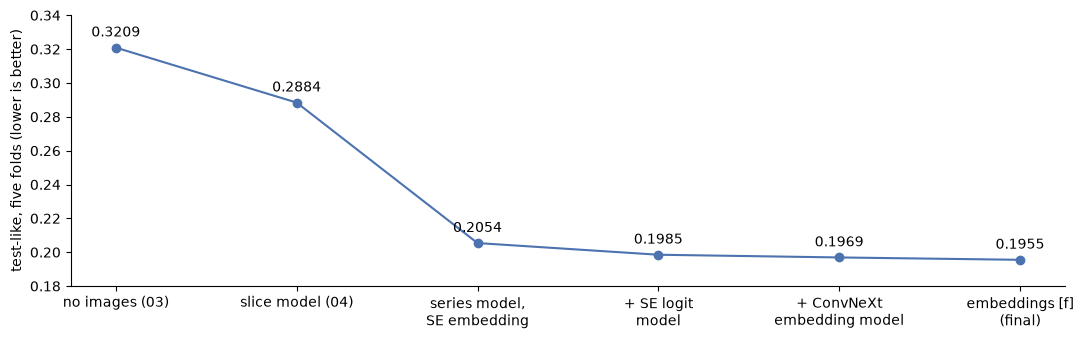

In [13]:
steps = {"no images (03)": TO_BEAT, "slice model (04)": SLICES_ONLY, "series model,\nSE embedding": scores(oof((REFERENCE,))[0])["test-like"],
         "+ SE logit\nmodel": scores(oof((SE, LOGIT))[0])["test-like"], "+ ConvNeXt\nembedding model": scores(oof((SE, LOGIT, CNX))[0])["test-like"], "embeddings [f]\n(final)": scores(final)["test-like"]}
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(range(len(steps)), list(steps.values()), "o-", color="#4C72B0")
for x, value in enumerate(steps.values()):
    ax.annotate(f"{value:.4f}", (x, value), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set_xticks(range(len(steps)), steps)
ax.set(ylabel="test-like, five folds (lower is better)", ylim=(0.18, 0.34))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

**Result:** the mean of three series models (SE-ResNeXt101 embedding [f], SE-ResNeXt101 logit [f, f − previous, f − next], ConvNeXt Tiny embedding [f]), one seed each, scores 0.1955 test-like and 0.1993 full over the five folds, against 0.2884 for the slice model alone and 0.3209 without images.

**Choices**

| Question | Chosen | Other options |
|---|---|---|
| input | SE embedding: 0.2054 | logit: 0.2062; both: 0.2056 |
| length | own: 0.2054 | 192 slices: 0.2053 |
| slice loss | series with PE: 0.2054 | every series: 0.2269 |
| two backbones | separate models averaged | joint embedding: 0.2443; joint logit: 0.2197 |
| ensemble | SE embedding + SE logit + ConvNeXt embedding: 0.1969 | with ConvNeXt logit: 0.1972; all four: 0.1979; SE pair: 0.1985 |
| neighbour differences | [f] for the embedding models, with them for SE logit: 0.1955 | with them in all three: 0.1969; [f] in all three: 0.1957 |
| seeds | 1 | 3, for the section 5 set: 0.1966 against 0.1969 |

**Limits**
- **The series models train on in-sample features and are scored on out-of-sample ones.** Out-of-fold features inside the training folds would remove the mismatch but need 10 more slice models per backbone.
- The ensemble and its inputs were chosen among about fifteen sets on the same out-of-fold series they are scored on; the size of the optimism is unknown.
- Each validation series is scored by one fold's ensemble; the test set gets the mean of the five folds' ensembles before the fix, which is not measured here.
- **The final runs one seed per model:** three seeds gained 0.0003 for the section 5 set.
- Sections 2–6 rest on one seed (section 5 adds second seeds as controls); the intervals cover the choice of series, not retraining or selection.
- The model's settings (size, learning rate, epochs, dropout) come from the 1st place solution and were not tuned.
- Both backbones mean all 10 slice models run on the test set: about 6.5 of Kaggle's 9 hours by the benchmark of 04, not yet tested end to end.